# Plot JAXMD benchmark

Average runtime of the reverse-mode gradient for the `jaxmd20` benchmark, per pass pipeline and AD placement.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# works whether the notebook is run from the repo root or from `results/`
path = Path("results_JAXMD.json")
if not path.exists():
    path = Path("..") / path

# one row per sample (memory is null when xprof recorded no memory profile, e.g. on CPU)
samples = pd.read_json(path).explode(["time_s", "peak_memory_bytes"])
samples = samples.astype({"time_s": float, "peak_memory_bytes": float})
samples

,benchmark,pipeline,backend,key,time_s,peak_memory_bytes
0,jaxmd20,JaXPipe,cuda,Primal,0.000794,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000837,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000830,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000840,437296640.0
0,jaxmd20,JaXPipe,cuda,Primal,0.000892,437296640.0
...,...,...,...,...,...,...
32,jaxmd20,IDefOpt,cuda,BothRev,0.001509,172748544.0
32,jaxmd20,IDefOpt,cuda,BothRev,0.001504,172748544.0
32,jaxmd20,IDefOpt,cuda,BothRev,0.001516,172748544.0
32,jaxmd20,IDefOpt,cuda,BothRev,0.001523,172748544.0


In [3]:
# one row per (benchmark, pipeline, backend, key) with the statistics over the samples
df = (
    samples.groupby(["benchmark", "pipeline", "backend", "key"], sort=False)
    .agg(
        nsamples=("time_s", "size"),
        time_avg_s=("time_s", "mean"),
        time_std_s=("time_s", "std"),
        time_min_s=("time_s", "min"),
        time_max_s=("time_s", "max"),
        mem_avg_bytes=("peak_memory_bytes", "mean"),
        mem_std_bytes=("peak_memory_bytes", "std"),
        mem_min_bytes=("peak_memory_bytes", "min"),
        mem_max_bytes=("peak_memory_bytes", "max"),
    )
    .reset_index()
)
df

,benchmark,pipeline,backend,key,nsamples,time_avg_s,time_std_s,time_min_s,time_max_s,mem_avg_bytes,mem_std_bytes,mem_min_bytes,mem_max_bytes
0,jaxmd20,JaXPipe,cuda,Primal,12,0.000868,0.000036,0.000794,0.000913,437296640.0,0.0,437296640.0,437296640.0
1,jaxmd20,Jax,cuda,Primal,12,0.000850,0.000037,0.000794,0.000911,437586176.0,0.0,437586176.0,437586176.0
2,jaxmd20,HLOOpt,cuda,Primal,12,0.000879,0.000013,0.000849,0.000901,169745664.0,0.0,169745664.0,169745664.0
3,jaxmd20,PartOpt,cuda,Primal,12,0.000927,0.000050,0.000860,0.001002,212948480.0,0.0,212948480.0,212948480.0
4,jaxmd20,IPartOpt,cuda,Primal,12,0.000914,0.000042,0.000829,0.000967,212948480.0,0.0,212948480.0,212948480.0
5,jaxmd20,DefOpt,cuda,Primal,12,0.000463,0.000008,0.000448,0.000476,308082688.0,0.0,308082688.0,308082688.0
6,jaxmd20,IDefOpt,cuda,Primal,12,0.000468,0.000009,0.000450,0.000488,169746432.0,0.0,169746432.0,169746432.0
7,jaxmd20,JaXPipe,cuda,Forward,12,0.000804,0.000021,0.000775,0.000832,283132160.0,0.0,283132160.0,283132160.0
8,jaxmd20,Jax,cuda,Forward,12,0.001232,0.000017,0.001214,0.001267,438845952.0,0.0,438845952.0,438845952.0
9,jaxmd20,HLOOpt,cuda,Forward,12,0.000762,0.000007,0.000753,0.000777,171009024.0,0.0,171009024.0,171009024.0


In [4]:
# key -> group label
KEYS = {
    "PreRev": "Pre AD",
    "PostRev": "Post AD",
    "BothRev": "Pre + Post AD",
}

# pass pipeline -> legend label
PIPELINES = {
    "HLOOpt": "HLO Opts.",
    "DefOpt": "All (No Inline)",
    "IDefOpt": "All (Inline)",
}

COLORS = {
    "HLOOpt": "#fc8d62",
    "DefOpt": "#66c2a5",
    "IDefOpt": "#8da0cb",
}

avg = df.pivot_table(index="key", columns="pipeline", values="time_avg_s")  # seconds
baseline = avg.loc["BothRev", "Jax"]  # "No opt"

avg.loc[list(KEYS), list(PIPELINES)].assign(**{"No opt (Jax)": baseline})

pipeline,HLOOpt,DefOpt,IDefOpt,No opt (Jax)
key,,,,
PreRev,0.001369,0.001381,0.001408,0.004279
PostRev,0.004040,0.003220,0.001476,0.004279
BothRev,0.001466,0.001486,0.001507,0.004279


## Runtime

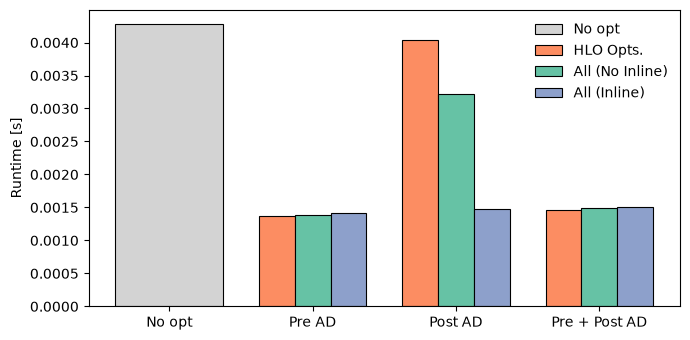

In [5]:
width = 0.25
bar_kw = dict(edgecolor="black", linewidth=0.8)

fig, ax = plt.subplots(figsize=(7, 3.5))

# "No opt" group: single wide bar
ax.bar(0, baseline, width=len(PIPELINES) * width, color="lightgray", label="No opt", **bar_kw)

# Pre AD / Post AD / Pre + Post AD groups
x = np.arange(1, len(KEYS) + 1)
offsets = (np.arange(len(PIPELINES)) - (len(PIPELINES) - 1) / 2) * width
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, avg.loc[list(KEYS), pipe], width, color=COLORS[pipe], label=label, **bar_kw)

ax.set_xticks(np.arange(len(KEYS) + 1), ["No opt", *KEYS.values()])
ax.set_ylabel("Runtime [s]")
ax.legend(frameon=False)
fig.tight_layout()

# fig.savefig("jaxmd20-runtime.pdf", bbox_inches="tight")
plt.show()

### Speedup over JAX

In [6]:
# speedup w.r.t. "No opt" (Jax, BothRev): > 1 means faster than the baseline
speedup = (baseline / avg.loc[list(KEYS), list(PIPELINES)]).rename(index=KEYS, columns=PIPELINES)
speedup.round(2)

pipeline,HLO Opts.,All (No Inline),All (Inline)
key,,,
Pre AD,3.13,3.10,3.04
Post AD,1.06,1.33,2.90
Pre + Post AD,2.92,2.88,2.84


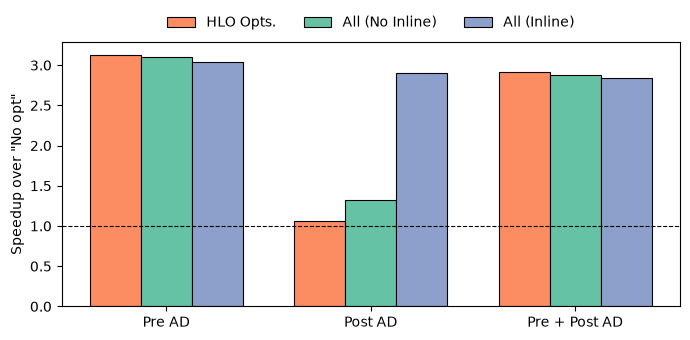

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))

x = np.arange(len(KEYS))
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, speedup[label], width, color=COLORS[pipe], label=label, **bar_kw)

ax.axhline(1, color="black", linestyle="--", linewidth=0.8)  # "No opt" baseline
ax.set_xticks(x, list(KEYS.values()))
ax.set_ylabel('Speedup over "No opt"')
ax.legend(frameon=False, ncols=len(PIPELINES), loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()

# fig.savefig("jaxmd20-speedup.pdf", bbox_inches="tight")
plt.show()

## Memory usage

In [8]:
# peak device memory over the samples, in MiB
mem = df.pivot_table(index="key", columns="pipeline", values="mem_avg_bytes") / 2**20
mem_baseline = mem.loc["BothRev", "Jax"]  # "No opt"

mem.loc[list(KEYS), list(PIPELINES)].assign(**{"No opt (Jax)": mem_baseline})

pipeline,HLOOpt,DefOpt,IDefOpt,No opt (Jax)
key,,,,
PreRev,164.838867,164.838867,164.838867,420.143311
PostRev,164.794678,296.608154,164.758789,420.143311
BothRev,164.745850,164.745850,164.745850,420.143311


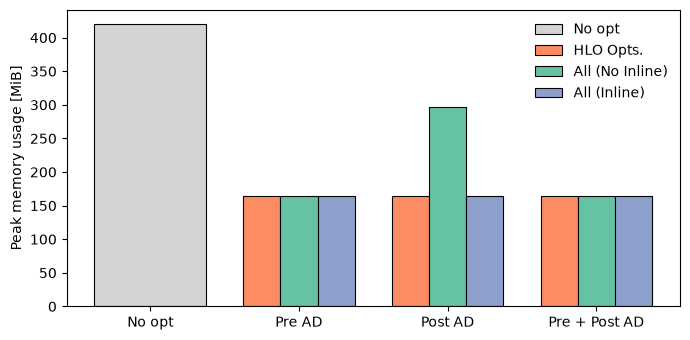

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))

# "No opt" group: single wide bar
ax.bar(0, mem_baseline, width=len(PIPELINES) * width, color="lightgray", label="No opt", **bar_kw)

# Pre AD / Post AD / Pre + Post AD groups
x = np.arange(1, len(KEYS) + 1)
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, mem.loc[list(KEYS), pipe], width, color=COLORS[pipe], label=label, **bar_kw)

ax.set_xticks(np.arange(len(KEYS) + 1), ["No opt", *KEYS.values()])
ax.set_ylabel("Peak memory usage [MiB]")
ax.legend(frameon=False)
fig.tight_layout()

# fig.savefig("jaxmd20-memory.pdf", bbox_inches="tight")
plt.show()